In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
DOCS = ROOT / "docs"

assert RAW.is_dir(), f"Cannot find data folder: {RAW}"

PROCESSED.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("Data folder:", RAW)

Project folder: c:\local\supplyshield
Data folder: c:\local\supplyshield\data\raw


In [2]:
d = pd.read_csv(RAW / "delhivery_data.csv")

print("Original shape:", d.shape)
print("Duplicate rows:", d.duplicated().sum())

d = d.drop_duplicates().copy()

dates = pd.to_datetime(
    d["trip_creation_time"],
    errors="coerce"
)

print("Date range:", dates.min(), "->", dates.max())
print("Missing or invalid dates:", dates.isna().sum())

print("\nRoute types:")
print(d["route_type"].value_counts(dropna=False))

Original shape: (144867, 24)
Duplicate rows: 0
Date range: 2018-09-12 00:00:16.535741 -> 2018-10-03 23:59:42.701692
Missing or invalid dates: 0

Route types:
route_type
FTL        99660
Carting    45207
Name: count, dtype: int64


In [3]:
# Columns identifying one journey leg
keys = [
    "trip_uuid",
    "source_center",
    "destination_center",
    "od_start_time",
    "od_end_time",
]

# Check for missing identifiers
missing_keys = d[keys].isna().any(axis=1)
print("Rows with missing leg identifiers:", missing_keys.sum())

clean = d.loc[~missing_keys].copy()

# Make sure travel times and distances are numeric
for col in ["actual_time", "osrm_time", "osrm_distance"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

# Combine scan records into one row per leg
legs = (
    clean.groupby(keys, as_index=False)
    .agg(
        trip_creation_time=("trip_creation_time", "first"),
        source_name=("source_name", "first"),
        destination_name=("destination_name", "first"),
        route_type=("route_type", "first"),
        actual_time_min=("actual_time", "max"),
        osrm_time_min=("osrm_time", "max"),
        osrm_distance_km=("osrm_distance", "max"),
        scan_rows=("trip_uuid", "size"),
    )
)

# Calculate a ratio only when travel times are valid
valid = (
    np.isfinite(legs["actual_time_min"])
    & np.isfinite(legs["osrm_time_min"])
    & (legs["actual_time_min"] >= 0)
    & (legs["osrm_time_min"] > 0)
)

legs["delay_ratio"] = np.nan

legs.loc[valid, "delay_ratio"] = (
    legs.loc[valid, "actual_time_min"]
    / legs.loc[valid, "osrm_time_min"]
)

print("Legs shape:", legs.shape)
print("Legs without a valid ratio:", (~valid).sum())

display(legs.head())

Rows with missing leg identifiers: 0
Legs shape: (26369, 14)
Legs without a valid ratio: 0


,trip_uuid,source_center,destination_center,od_start_time,od_end_time,trip_creation_time,source_name,destination_name,route_type,actual_time_min,osrm_time_min,osrm_distance_km,scan_rows,delay_ratio
0,trip-153671041653548748,IND209304AAA,IND000000ACB,2018-09-12 16:39:46.858469,2018-09-13 13:40:23.123744,2018-09-12 00:00:16.535741,Kanpur_Central_H_6 (Uttar Pradesh),Gurgaon_Bilaspur_HB (Haryana),FTL,732.0,349.0,446.5496,18,2.097421
1,trip-153671041653548748,IND462022AAA,IND209304AAA,2018-09-12 00:00:16.535741,2018-09-12 16:39:46.858469,2018-09-12 00:00:16.535741,Bhopal_Trnsport_H (Madhya Pradesh),Kanpur_Central_H_6 (Uttar Pradesh),FTL,830.0,394.0,544.8027,21,2.106599
2,trip-153671042288605164,IND561203AAB,IND562101AAA,2018-09-12 02:03:09.655591,2018-09-12 03:01:59.598855,2018-09-12 00:00:22.886430,Doddablpur_ChikaDPP_D (Karnataka),Chikblapur_ShntiSgr_D (Karnataka),Carting,47.0,26.0,28.1994,3,1.807692
3,trip-153671042288605164,IND572101AAA,IND561203AAB,2018-09-12 00:00:22.886430,2018-09-12 02:03:09.655591,2018-09-12 00:00:22.886430,Tumkur_Veersagr_I (Karnataka),Doddablpur_ChikaDPP_D (Karnataka),Carting,96.0,42.0,56.9116,6,2.285714
4,trip-153671043369099517,IND000000ACB,IND160002AAC,2018-09-14 03:40:17.106733,2018-09-14 17:34:55.442454,2018-09-12 00:00:33.691250,Gurgaon_Bilaspur_HB (Haryana),Chandigarh_Mehmdpur_H (Punjab),FTL,611.0,212.0,281.2109,12,2.882075


In [4]:
# Group journey legs by source and destination
lanes = (
    legs.groupby(
        ["source_center", "destination_center"],
        as_index=False
    )
    .agg(
        source_name=("source_name", "first"),
        destination_name=("destination_name", "first"),
        leg_count=("trip_uuid", "size"),
        trip_count=("trip_uuid", "nunique"),
        valid_ratio_count=("delay_ratio", "count"),
        median_delay_ratio=("delay_ratio", "median"),
        mean_delay_ratio=("delay_ratio", "mean"),
        median_distance_km=("osrm_distance_km", "median"),
    )
    .sort_values("trip_count", ascending=False)
)

# Count distinct locations appearing as sources or destinations
hubs = pd.unique(
    pd.concat(
        [legs["source_center"], legs["destination_center"]],
        ignore_index=True
    )
)

print("Legs shape:", legs.shape)
print("Lanes shape:", lanes.shape)
print("Unique trips:", legs["trip_uuid"].nunique())
print("Hub count:", len(hubs))
print("Directed lane count:", len(lanes))

print(
    "Lanes with at least 30 distinct trips:",
    (lanes["trip_count"] >= 30).sum()
)

print("\nDelay ratio summary:")
print(
    legs["delay_ratio"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print("\nTop 10 lanes by distinct trip count:")
display(lanes.head(10))

Legs shape: (26369, 14)
Lanes shape: (2783, 10)
Unique trips: 14817
Hub count: 1657
Directed lane count: 2783
Lanes with at least 30 distinct trips: 99

Delay ratio summary:
count    26369.000000
mean         2.541076
std          2.606560
min          0.387755
50%          2.000000
90%          3.760928
95%          5.176708
99%         11.954667
max         77.387097
Name: delay_ratio, dtype: float64

Top 10 lanes by distinct trip count:


,source_center,destination_center,source_name,destination_name,leg_count,trip_count,valid_ratio_count,median_delay_ratio,mean_delay_ratio,median_distance_km
1775,IND562132AAA,IND560300AAA,Bangalore_Nelmngla_H (Karnataka),Bengaluru_KGAirprt_HB (Karnataka),151,151,151,1.723404,1.826611,38.23000
1774,IND562132AAA,IND560099AAB,Bangalore_Nelmngla_H (Karnataka),Bengaluru_Bomsndra_HB (Karnataka),127,127,127,1.666667,1.819340,50.10480
1719,IND560099AAB,IND560300AAA,Bengaluru_Bomsndra_HB (Karnataka),Bengaluru_KGAirprt_HB (Karnataka),121,121,121,1.833333,2.006086,54.34860
1735,IND560300AAA,IND562132AAA,Bengaluru_KGAirprt_HB (Karnataka),Bangalore_Nelmngla_H (Karnataka),108,108,108,1.801961,2.060190,42.22360
1080,IND411033AAA,IND421302AAG,Pune_Tathawde_H (Maharashtra),Bhiwandi_Mankoli_HB (Maharashtra),107,107,107,1.990476,2.174548,129.64870
1152,IND421302AAG,IND400072AAB,Bhiwandi_Mankoli_HB (Maharashtra),Mumbai Hub (Maharashtra),105,105,105,2.545455,2.716863,27.31490
1720,IND560099AAB,IND562132AAA,Bengaluru_Bomsndra_HB (Karnataka),Bangalore_Nelmngla_H (Karnataka),102,102,102,1.518519,1.718411,46.42785
68,IND000000ACT,IND000000ACB,Delhi_Gateway_HB (Delhi),Gurgaon_Bilaspur_HB (Haryana),100,100,100,1.358553,1.683666,43.65860
1010,IND400072AAD,IND421302AAG,Mumbai_Chndivli_PC (Maharashtra),Bhiwandi_Mankoli_HB (Maharashtra),99,99,99,2.727273,3.774982,25.67000
38,IND000000ACB,IND131028AAB,Gurgaon_Bilaspur_HB (Haryana),Sonipat_Kundli_H (Haryana),92,92,92,2.074076,2.200456,104.68780


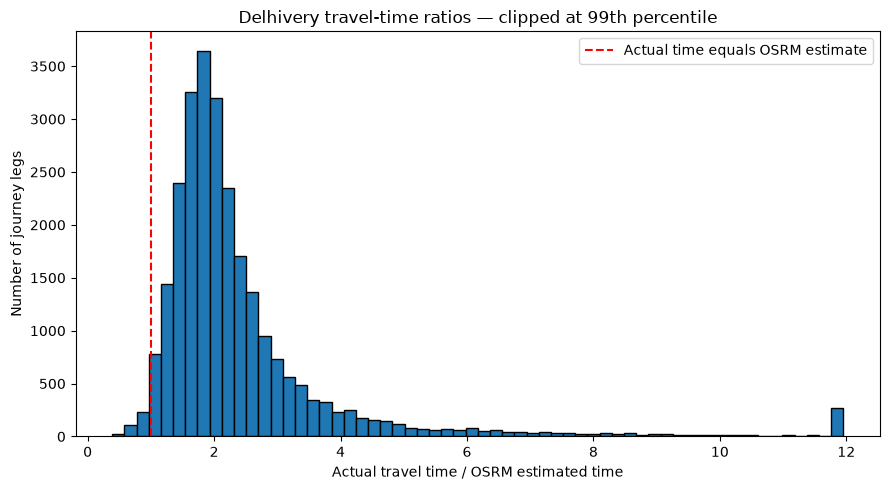

Saved: c:\local\supplyshield\data\processed\legs.csv
Saved: c:\local\supplyshield\data\processed\lanes.csv
Saved: c:\local\supplyshield\docs\delay_ratio_hist.png


In [5]:
# Save the processed tables
legs.to_csv(PROCESSED / "legs.csv", index=False)
lanes.to_csv(PROCESSED / "lanes.csv", index=False)

# Get valid travel-time ratios
ratios = legs["delay_ratio"].dropna()

# Clip only the graph at the 99th percentile
# to keep extreme values from stretching the horizontal axis
upper = float(ratios.quantile(0.99))

plt.figure(figsize=(9, 5))
plt.hist(ratios.clip(upper=upper), bins=60, edgecolor="black")

plt.axvline(
    1,
    color="red",
    linestyle="--",
    label="Actual time equals OSRM estimate"
)

plt.xlabel("Actual travel time / OSRM estimated time")
plt.ylabel("Number of journey legs")
plt.title("Delhivery travel-time ratios — clipped at 99th percentile")
plt.legend()
plt.tight_layout()

plt.savefig(DOCS / "delay_ratio_hist.png", dpi=150)
plt.show()

print("Saved:", PROCESSED / "legs.csv")
print("Saved:", PROCESSED / "lanes.csv")
print("Saved:", DOCS / "delay_ratio_hist.png")

Original shape: (99441, 8)
Orders excluded for missing/invalid dates: 2965
Usable shape: (96476, 9)

Delay in days:
count    96476.000000
mean       -11.876881
std         10.183854
min       -147.000000
50%        -12.000000
90%         -2.000000
95%          3.000000
99%         18.000000
max        188.000000
Name: delay_days, dtype: float64


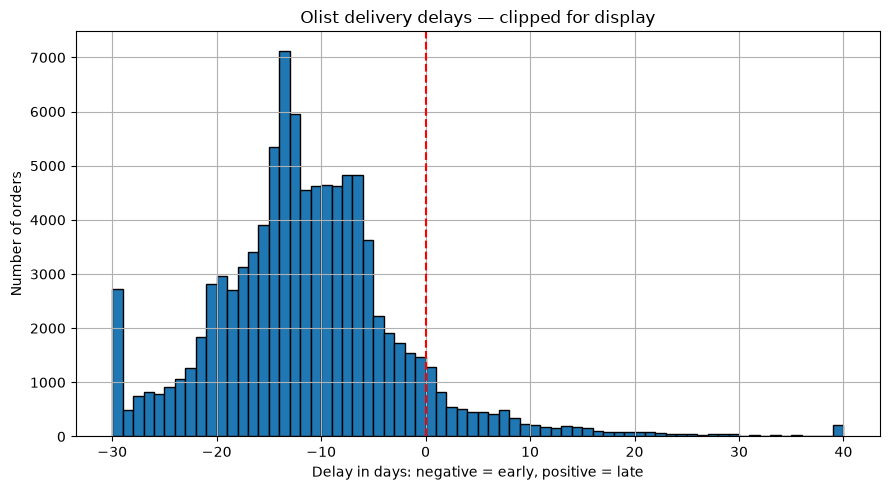

Saved: c:\local\supplyshield\docs\olist_delay_hist.png


In [6]:
# Load Olist orders
o = pd.read_csv(RAW / "olist_orders_dataset.csv")

print("Original shape:", o.shape)

# Convert delivery dates into datetime values
date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    o[col] = pd.to_datetime(o[col], errors="coerce")

# Keep orders with both dates available
missing_dates = o[date_columns].isna().any(axis=1)
print("Orders excluded for missing/invalid dates:", missing_dates.sum())

o = o.loc[~missing_dates].copy()

# Actual delivery date minus estimated delivery date
o["delay_days"] = (
    o["order_delivered_customer_date"]
    - o["order_estimated_delivery_date"]
).dt.days

print("Usable shape:", o.shape)

print("\nDelay in days:")
print(
    o["delay_days"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

# Clip only the graph; keep original values in the table
plt.figure(figsize=(9, 5))
o["delay_days"].clip(-30, 40).hist(
    bins=70,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Delay in days: negative = early, positive = late")
plt.ylabel("Number of orders")
plt.title("Olist delivery delays — clipped for display")
plt.tight_layout()
plt.savefig(DOCS / "olist_delay_hist.png", dpi=150)
plt.show()

print("Saved:", DOCS / "olist_delay_hist.png")

In [7]:
print("Usable orders:", len(o))
print(o["delay_days"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Usable orders: 96476
count    96476.000000
mean       -11.876881
std         10.183854
min       -147.000000
50%        -12.000000
90%         -2.000000
95%          3.000000
99%         18.000000
max        188.000000
Name: delay_days, dtype: float64


In [8]:
olist_raw = pd.read_csv(RAW / "olist_orders_dataset.csv")

purchase_dates = pd.to_datetime(
    olist_raw["order_purchase_timestamp"],
    errors="coerce"
)

print("Original Olist rows:", len(olist_raw))
print("Usable Olist orders:", len(o))
print("Purchase date range:",
      purchase_dates.min(), "->", purchase_dates.max())

Original Olist rows: 99441
Usable Olist orders: 96476
Purchase date range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18
